# Reducción de la pobreza gracias a las prestaciones que no son pensiones

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "reduccion-pobreza-transferencias"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Reducción de la pobreza gracias a las prestaciones que no son pensiones"  # `titulo` en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de reducción de la tasa de riesgo de pobreza"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/
MAX_DIF_METODO = 0.05  # puntos: diferencia máxima admitida entre el cálculo propio y tespm050 en los años comunes

## 1. Contexto

**Qué mide.** En qué porcentaje baja la tasa de riesgo de pobreza de toda la población al sumar a la renta de los hogares las prestaciones sociales distintas de las pensiones: desempleo, familia e hijos, incapacidad, vivienda, ingreso mínimo y otras ayudas. Se calcula comparando la tasa de riesgo de pobreza *antes* de esas prestaciones con la tasa *después* de ellas, con el mismo umbral (el 60 % de la renta mediana).

**Cómo se lee.** Un valor de 25 significa que esas prestaciones reducen en un 25 % el número de personas en riesgo de pobreza: si sin ellas habría 28 de cada 100, con ellas hay 21. Cuanto más alto, más personas sacan las prestaciones de debajo del umbral.

**Limitaciones.**
- Las **pensiones se cuentan como renta antes de las transferencias**: el indicador mide solo el efecto del resto de prestaciones.
- Mide a cuántas personas sacan las prestaciones del riesgo de pobreza, **no cuántas de las que lo necesitan las cobran** ni cuánto se acercan al umbral quienes siguen por debajo.
- Es un cálculo estático: no tiene en cuenta que, sin prestaciones, algunas personas se comportarían de otra forma (por ejemplo, trabajando más horas).
- Sale de la encuesta de condiciones de vida (EU-SILC): el año de la gráfica es el de la encuesta y los ingresos son los del año anterior. En España, de 1995 a 2001 las tasas salen del Panel de Hogares de la Unión Europea (PHOGUE) y en 2002 de otra fuente, redondeadas a números enteros; Eurostat marca rupturas de serie en 2002 y 2004 y no hay dato de 2003.
- **Solo Europa.** La base de distribución de la renta de la OCDE solo publica la pobreza antes y después de *todos* los impuestos y transferencias, pensiones incluidas: la OCDE, EE. UU. y Canadá quedan vacíos.

## 2. Descarga

Eurostat, España y UE-27, ambos sexos, toda la población, umbral del 60 % de la mediana (`B_60`, `MED_EI`):
- `tespm050`: impacto de las transferencias sociales (sin pensiones) en la reducción de la pobreza, en % (la serie de la gráfica desde que se publica).
- `ilc_li10`: tasa de riesgo de pobreza antes de las transferencias sociales, con las pensiones en la renta (no como transferencia).
- `ilc_li02`: tasa de riesgo de pobreza después de las transferencias.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, oecd
from lib.tipos import FuenteMeta

BASE = {"freq": "A", "sex": "T", "age": "TOTAL", "unit": "PC", "statinfo": "MED_EI", "rskpovth": "B_60"}
tesp, fuentes_tesp = eurostat.get("tespm050", BASE, desde=DESDE)
antes, _ = eurostat.get("ilc_li10", BASE, desde=DESDE)
despues, _ = eurostat.get("ilc_li02", BASE, desde=DESDE)

## 3. Transformación

1. Se reproduce `tespm050` con su definición: (tasa antes de las transferencias − tasa después) / tasa antes × 100, con `ilc_li10` e `ilc_li02`, y se comprueba que coincide en todos los años en que Eurostat la publica.
2. La serie de la gráfica es `tespm050`; en los años anteriores a su primer dato se usa el mismo cálculo.

In [ ]:
serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"]
filas, primero_tesp, comprobacion = [], {}, {}
for g in ("espana", "ue27"):
    t = pd.DataFrame({"tespm050": serie(tesp, g), "antes": serie(antes, g), "después": serie(despues, g)})
    t["cálculo"] = (t["antes"] - t["después"]) / t["antes"] * 100
    comun = t.dropna(subset=["tespm050", "cálculo"])
    dif = (comun["cálculo"] - comun["tespm050"]).abs().max()
    assert dif <= MAX_DIF_METODO, f"{g}: el cálculo no reproduce tespm050 (diferencia {dif:.3f})"
    comprobacion[g] = dif
    primero_tesp[g] = int(t["tespm050"].dropna().index.min())
    valor = t["tespm050"].combine_first(t["cálculo"].loc[: primero_tesp[g] - 1])
    valor = valor.dropna()
    filas.append(pd.DataFrame({"serie": g, "periodo": valor.index, "valor": valor.values}))
    print(g, f"diferencia máxima cálculo − tespm050: {dif:.3f}; tespm050 desde {primero_tesp[g]}")
    display(t.round(2).loc[: primero_tesp[g] + 1])
df = pd.concat(filas, ignore_index=True)
HOY = fuentes_tesp[0].fecha_consulta
fuentes = [
    FuenteMeta(f.serie, f.organismo,
               "tespm050 (sex=T, age=TOTAL, B_60); años anteriores: (ilc_li10 − ilc_li02) / ilc_li10 × 100",
               f.url, f.fecha_consulta)
    for f in fuentes_tesp
]
IDD = (oecd.ORGANISMO, "DSD_WISE_IDD@DF_IDD: sin la pobreza antes de las transferencias que no son pensiones", oecd.URL_EXPLORER)
df = pd.concat([df, pd.DataFrame({"serie": ["ocde", "eeuu", "canada"], "periodo": DESDE, "valor": float("nan")})], ignore_index=True)
fuentes += [FuenteMeta(s, *IDD[:2], IDD[2], HOY) for s in ("ocde", "eeuu", "canada")]
anios_es = sorted(df[(df["serie"] == "espana") & df["valor"].notna()]["periodo"])
FALTAN_ES = sorted(set(range(anios_es[0], anios_es[-1] + 1)) - set(anios_es))
assert df["valor"].dropna().between(0, 100).all()

espana diferencia máxima cálculo − tespm050: 0.005; tespm050 desde 2005


,tespm050,antes,después,cálculo
periodo,,,,
1995,NaN,27.0,19.0,29.63
1996,NaN,26.0,18.0,30.77
1997,NaN,27.0,20.0,25.93
1998,NaN,25.0,18.0,28.00
1999,NaN,23.0,19.0,17.39
2000,NaN,22.0,18.0,18.18
2001,NaN,23.0,19.0,17.39
2002,NaN,22.0,19.0,13.64
2004,NaN,25.2,20.1,20.24


ue27 diferencia máxima cálculo − tespm050: 0.004; tespm050 desde 2015


,tespm050,antes,después,cálculo
periodo,,,,
2013,NaN,NaN,16.8,NaN
2014,NaN,NaN,17.3,NaN
2015,32.03,25.6,17.4,32.03
2016,31.64,25.6,17.5,31.64


### Notas

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


NOTAS = [
    f"España y UE-27: Eurostat, impacto de las transferencias sociales sin pensiones en la reducción de la pobreza "
    f"(tespm050), umbral del 60 % de la mediana. España, de {anios_es[0]} a {primero_tesp['espana'] - 1}: cálculo propio "
    f"con la misma definición, (tasa de riesgo de pobreza antes de transferencias, ilc_li10, menos la de después, "
    f"ilc_li02) entre la de antes, por 100; reproduce tespm050 en todos los años en que se publica.",
    f"Rupturas de serie en España en 2002 y 2004, según Eurostat: de {anios_es[0]} a 2001 las tasas salen del Panel "
    f"de Hogares de la Unión Europea (PHOGUE) y en 2002 de otra fuente, redondeadas a números enteros, y desde 2004 de "
    f"la encuesta de condiciones de vida (EU-SILC); sin dato en {unir(FALTAN_ES)}.",
    "Las pensiones se cuentan como renta antes de las transferencias: el indicador mide el efecto del resto de "
    "prestaciones (desempleo, familia, incapacidad, vivienda, ingreso mínimo). El año es el de la encuesta; los "
    "ingresos, los del año anterior.",
    "Mide a cuántas personas sacan las prestaciones del riesgo de pobreza, no cuántas de las que lo necesitan las cobran.",
    "OCDE, EE. UU. y Canadá: sin dato. La base de distribución de la renta de la OCDE solo publica la pobreza antes y "
    "después de todos los impuestos y transferencias, pensiones incluidas.",
]
for n in NOTAS:
    print("-", n)

- España y UE-27: Eurostat, impacto de las transferencias sociales sin pensiones en la reducción de la pobreza (tespm050), umbral del 60 % de la mediana. España, de 1995 a 2004: cálculo propio con la misma definición, (tasa de riesgo de pobreza antes de transferencias, ilc_li10, menos la de después, ilc_li02) entre la de antes, por 100; reproduce tespm050 en todos los años en que se publica.
- Rupturas de serie en España en 2002 y 2004, según Eurostat: de 1995 a 2001 las tasas salen del Panel de Hogares de la Unión Europea (PHOGUE) y en 2002 de otra fuente, redondeadas a números enteros, y desde 2004 de la encuesta de condiciones de vida (EU-SILC); sin dato en 2003.
- Las pensiones se cuentan como renta antes de las transferencias: el indicador mide el efecto del resto de prestaciones (desempleo, familia, incapacidad, vivienda, ingreso mínimo). El año es el de la encuesta; los ingresos, los del año anterior.
- Mide a cuántas personas sacan las prestaciones del riesgo de pobreza, no cuá

## 4. Visualización

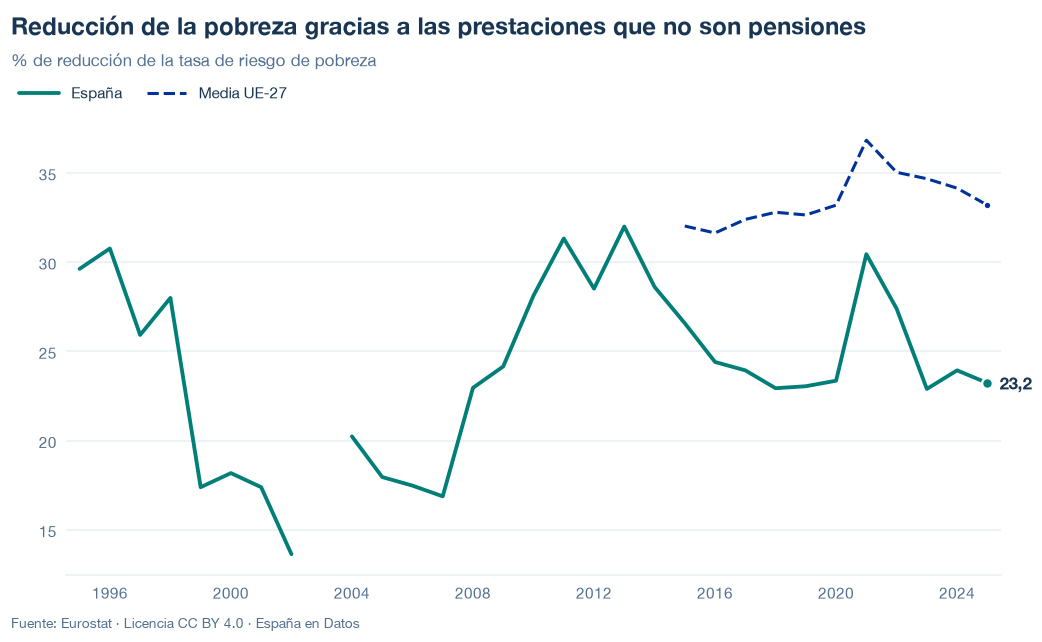

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/reduccion-pobreza-transferencias.json y data/reduccion-pobreza-transferencias.csv


## 6. Fuentes, notas y licencia

- Eurostat, `tespm050`, `ilc_li10` e `ilc_li02` (`T`, `TOTAL`, `B_60`, `MED_EI`, `PC`): España y UE-27.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.